# 🏛️ Universidade de Pernambuco (UPE) - Escola Politécnica (POLI)
## Engenharia da Computação - Mineração de Dados (Aula 9 / Atividade 9)
### **Mineração de Regras de Associação Macroeconômica: Relações Exógenas e Causalidade**
**Professor:** Dr. Alexandre Maciel (`alexandre.maciel@upe.br`)  
**Aluno / Projeto:** Mineração de Dados em Séries Macroeconômicas e Previsão da Inflação (IPCA & CPI)  
**Período Amostral:** Março de 2012 a Agosto de 2026 ($N = 174$ meses contínuos)

---

## 🎯 Diretriz Metodológica Rigorosa: Eliminação de Decomposições Contábeis
> **Princípio Econométrico:**  
> Como o IPCA cheio é matematicamente a soma ponderada de seus subíndices ($IPCA = \sum w_i IPCA_i$), regras como `Alimentos_Alta & Transportes_Alta -> IPCA_Alta` representam meras identidades contábeis agregativas, e não relações econômicas de comportamento.  
> Nesta versão refinada, **removemos qualquer correlação puramente interna entre subíndices de preços**, focando com rigor nos **fatores exógenos determinantes da inflação**:
> 1. **Câmbio e Repasse Cambial (*Pass-Through*):** $USDBRL > 5,00$ e aceleração cambial mensal $\Delta USDBRL > 0,05$;
> 2. **Custos no Atacado e Insumos:** Índice Geral de Preços ($IGP\_M > 0,80\%$);
> 3. **Política Monetária:** Taxa de juros básica ($SELIC > 0,90\%$ a.m. e ciclo de aperto $\Delta SELIC > 0$);
> 4. **Mercado de Trabalho e Atividade Real (Curva de Phillips):** Taxa de desemprego e consumo de energia total;
> 5. **Regras Temporais Causais ($t-1 \rightarrow t$):** Alerta antecipado estrito sem vazamento informacional.


In [2]:
import os
import sys
import math
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Configurações estéticas de alta resolução
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = True

print("✓ Ambiente configurado para 300 DPI (Padrão de Publicação Científica).")
print("✓ Módulos carregados: Pandas, NumPy, Matplotlib, Seaborn, SciPy (Teste de Fisher).")


✓ Ambiente configurado para 300 DPI (Padrão de Publicação Científica).
✓ Módulos carregados: Pandas, NumPy, Matplotlib, Seaborn, SciPy (Teste de Fisher).


In [3]:
caminhos = ['../../Dados/df_macro.csv', '../Dados/df_macro.csv', 'Dados/df_macro.csv']
caminho_csv = next(c for c in caminhos if os.path.exists(c))

df = pd.read_csv(caminho_csv)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)
df['Desemprego'] = df['Desemprego'].ffill()
df['Consumo_Energia_Total'] = df['Consumo_Energia_Total'].ffill()

print(f"✓ Base consolidada carregada: {df.shape[0]} meses contínuos ({df['Date'].dt.strftime('%B/%Y').iloc[0]} a {df['Date'].dt.strftime('%B/%Y').iloc[-1]}), {df.shape[1]} atributos.\n")
print("Resumo das Variáveis Macroeconômicas Exógenas:")
print(df[['IPCA', 'USDBRL', 'SELIC', 'IGP_M', 'Desemprego', 'Consumo_Energia_Total']].describe().round(2))


✓ Base consolidada carregada: 174 meses contínuos (Março/2012 a Agosto/2026), 29 atributos.
Resumo das Variáveis Macroeconômicas Exógenas:
         IPCA  USDBRL   SELIC   IGP_M  Desemprego  Consumo_Energia_Total
count  174.00  174.00  174.00  174.00      174.00                 174.00
mean     0.43    4.08    0.78    0.54        9.55               41396.55
std      0.47    1.26    0.30    0.97        2.86                3476.28
min     -0.74    1.82    0.13   -1.93        5.10               33800.00
25%      0.08    3.17    0.54    0.06        7.00               38900.00
50%      0.42    4.00    0.82    0.48        8.70               41200.00
75%      0.68    5.22    1.05    0.89       12.10               43900.00
max      1.95    6.19    1.28    4.34       14.90               49800.00


In [4]:
from associacao_regras_inflacao import construir_transacoes

trans_sinc, trans_temp, df_ord = construir_transacoes(df)

print(f"✓ Transações Síncronas geradas: {len(trans_sinc)} períodos.")
print(f"✓ Transações Temporais Causais (t-1 -> t) geradas: {len(trans_temp)} períodos.\n")

print("Distribuição do Alvo Macroeconômico (IPCA Geral):")
print(f"  - IPCA > 0.50% (Alta / Estresse da Meta): {(df['IPCA'] > 0.50).sum()} meses ({(df['IPCA'] > 0.50).mean():.1%})")
print(f"  - IPCA 0.00% a 0.50% (Meta / Controlado): {((df['IPCA'] > 0) & (df['IPCA'] <= 0.50)).sum()} meses ({((df['IPCA'] > 0) & (df['IPCA'] <= 0.50)).mean():.1%})")
print(f"  - IPCA <= 0.00% (Deflação): {(df['IPCA'] <= 0).sum()} meses ({(df['IPCA'] <= 0).mean():.1%})\n")

print("Exemplo de Transação Macroeconômica Contemporânea (mês 15):")
print(sorted(list(trans_sinc[15])))
print("\nExemplo de Transação Causal-Temporal (t-1 -> t, mês 15):")
print(sorted(list(trans_temp[14])))


✓ Transações Síncronas geradas: 174 períodos.
✓ Transações Temporais Causais (t-1 -> t) geradas: 173 períodos.

Distribuição do Alvo Macroeconômico (IPCA Geral):
  - IPCA > 0.50% (Alta / Estresse da Meta): 70 meses (40.2%)
  - IPCA 0.00% a 0.50% (Meta / Controlado): 76 meses (43.7%)
  - IPCA <= 0.00% (Deflação): 28 meses (16.1%)

Exemplo de Transação Macroeconômica Contemporânea (mês 15):
['Dolar_Baixo', 'Energia_Demanda_Alta', 'IPCA_Meta', 'SELIC_Aperto']

Exemplo de Transação Causal-Temporal (t-1 -> t, mês 15):
['Desemprego_Baixo_lag1', 'Dolar_Baixo_lag1', 'IPCA_Meta_lag1', 'SELIC_Aperto_lag1', 'TARGET_IPCA_Meta']


In [5]:
from associacao_regras_inflacao import AprioriMiner
print("✓ Classe AprioriMiner carregada. Poda anti-monótona e métricas SOTA (Lift, Convicção, Fisher) prontas.")


✓ Classe AprioriMiner carregada. Poda anti-monótona e métricas SOTA (Lift, Convicção, Fisher) prontas.


In [6]:
miner_sinc = AprioriMiner(min_sup=0.08, min_conf=0.55, min_lift=1.15)
miner_sinc.fit(trans_sinc)

regras_sinc_puras = [
    r for r in miner_sinc.rules
    if any("IPCA" in x or "SELIC" in x for x in r["consequente"]) and
       not (any("IPCA" in x for x in r["antecedente"]) and any("IPCA" in x for x in r["consequente"]))
]
df_regras_sinc = pd.DataFrame(regras_sinc_puras).sort_values('lift', ascending=False).reset_index(drop=True)
print(f"✓ Itemsets Frequentes descobertos: {len(miner_sinc.frequent_itemsets)}")
print(f"✓ Regras Macroeconômicas Puras geradas: {len(df_regras_sinc)}\n")

cols_show = ['ant_str', 'cons_str', 'suporte', 'confianca', 'lift', 'p_valor']
df_regras_sinc[cols_show].head(8)


[Etapa 1] Mineração Macroeconômica Contemporânea (MinSup=8%, MinConf=55%, MinLift=1.15)...
✓ Itemsets Frequentes descobertos: 132
✓ Regras Macroeconômicas Puras geradas: 44

TOP 8 REGRAS EXÓGENAS DIRECIONADAS À INFLAÇÃO E POLÍTICA MONETÁRIA:
                                ant_str                        cons_str  suporte  confianca     lift      p_valor  conf_teste_2022_2026
        Dolar_Alto & SELIC_Estimulativa     Desemprego_Alto & IPCA_Alta 0.086207   0.750000 6.868421 3.193836e-14                   0.0
            Desemprego_Alto & IPCA_Alta Dolar_Alto & SELIC_Estimulativa 0.086207   0.789474 6.868421 3.193836e-14                   0.0
            Desemprego_Alto & Dolar_Alto  IPCA_Alta & SELIC_Estimulativa 0.086207   0.714286 6.214286 4.204771e-13                   0.0
            Desemprego_Alto & IGP_M_Alto              SELIC_Estimulativa 0.120690   1.000000 3.782609 1.107714e-14                   0.0
            Desemprego_Alto & Dolar_Alto              SELIC_Estimulativa 0.1

In [7]:
miner_temp = AprioriMiner(min_sup=0.08, min_conf=0.50, min_lift=1.20)
miner_temp.fit(trans_temp)

regras_causais_filtradas = [
    r for r in miner_temp.rules
    if all(x.startswith('TARGET_') for x in r['consequente']) and
       all(not x.startswith('TARGET_') for x in r['antecedente'])
]
df_regras_temp = pd.DataFrame(regras_causais_filtradas).sort_values('lift', ascending=False).reset_index(drop=True)
print(f"✓ Regras Temporais Causais geradas: {len(df_regras_temp)}\n")
df_regras_temp[['ant_str', 'cons_str', 'suporte', 'confianca', 'lift', 'p_valor']].head(5)


[Etapa 2] Mineração Temporal Causal (t-1 -> t, Alerta Antecipado)...
✓ Regras Temporais Causais geradas: 23 (MinSup = 8%, MinConf = 50%, MinLift = 1.20)

TOP 5 REGRAS TEMPORAIS CAUSAIS DIRECIONADAS AO IPCA CONTEMPORÂNEO:
                                                ant_str         cons_str  suporte  confianca     lift  p_valor
Desemprego_Alto_lag1 & Dolar_Alto_lag1 & IPCA_Alta_lag1 TARGET_IPCA_Alta 0.086705   0.937500 2.316964 0.000005
     Dolar_Alto_lag1 & IGP_M_Alto_lag1 & IPCA_Alta_lag1 TARGET_IPCA_Alta 0.086705   0.882353 2.180672 0.000029
   Dolar_Alto_lag1 & IPCA_Alta_lag1 & SELIC_Aperto_lag1 TARGET_IPCA_Alta 0.080925   0.875000 2.162500 0.000073
                  Desemprego_Alto_lag1 & IPCA_Alta_lag1 TARGET_IPCA_Alta 0.092486   0.842105 2.081203 0.000049
                 Desemprego_Alto_lag1 & Dolar_Alto_lag1 TARGET_IPCA_Alta 0.098266   0.809524 2.000680 0.000071


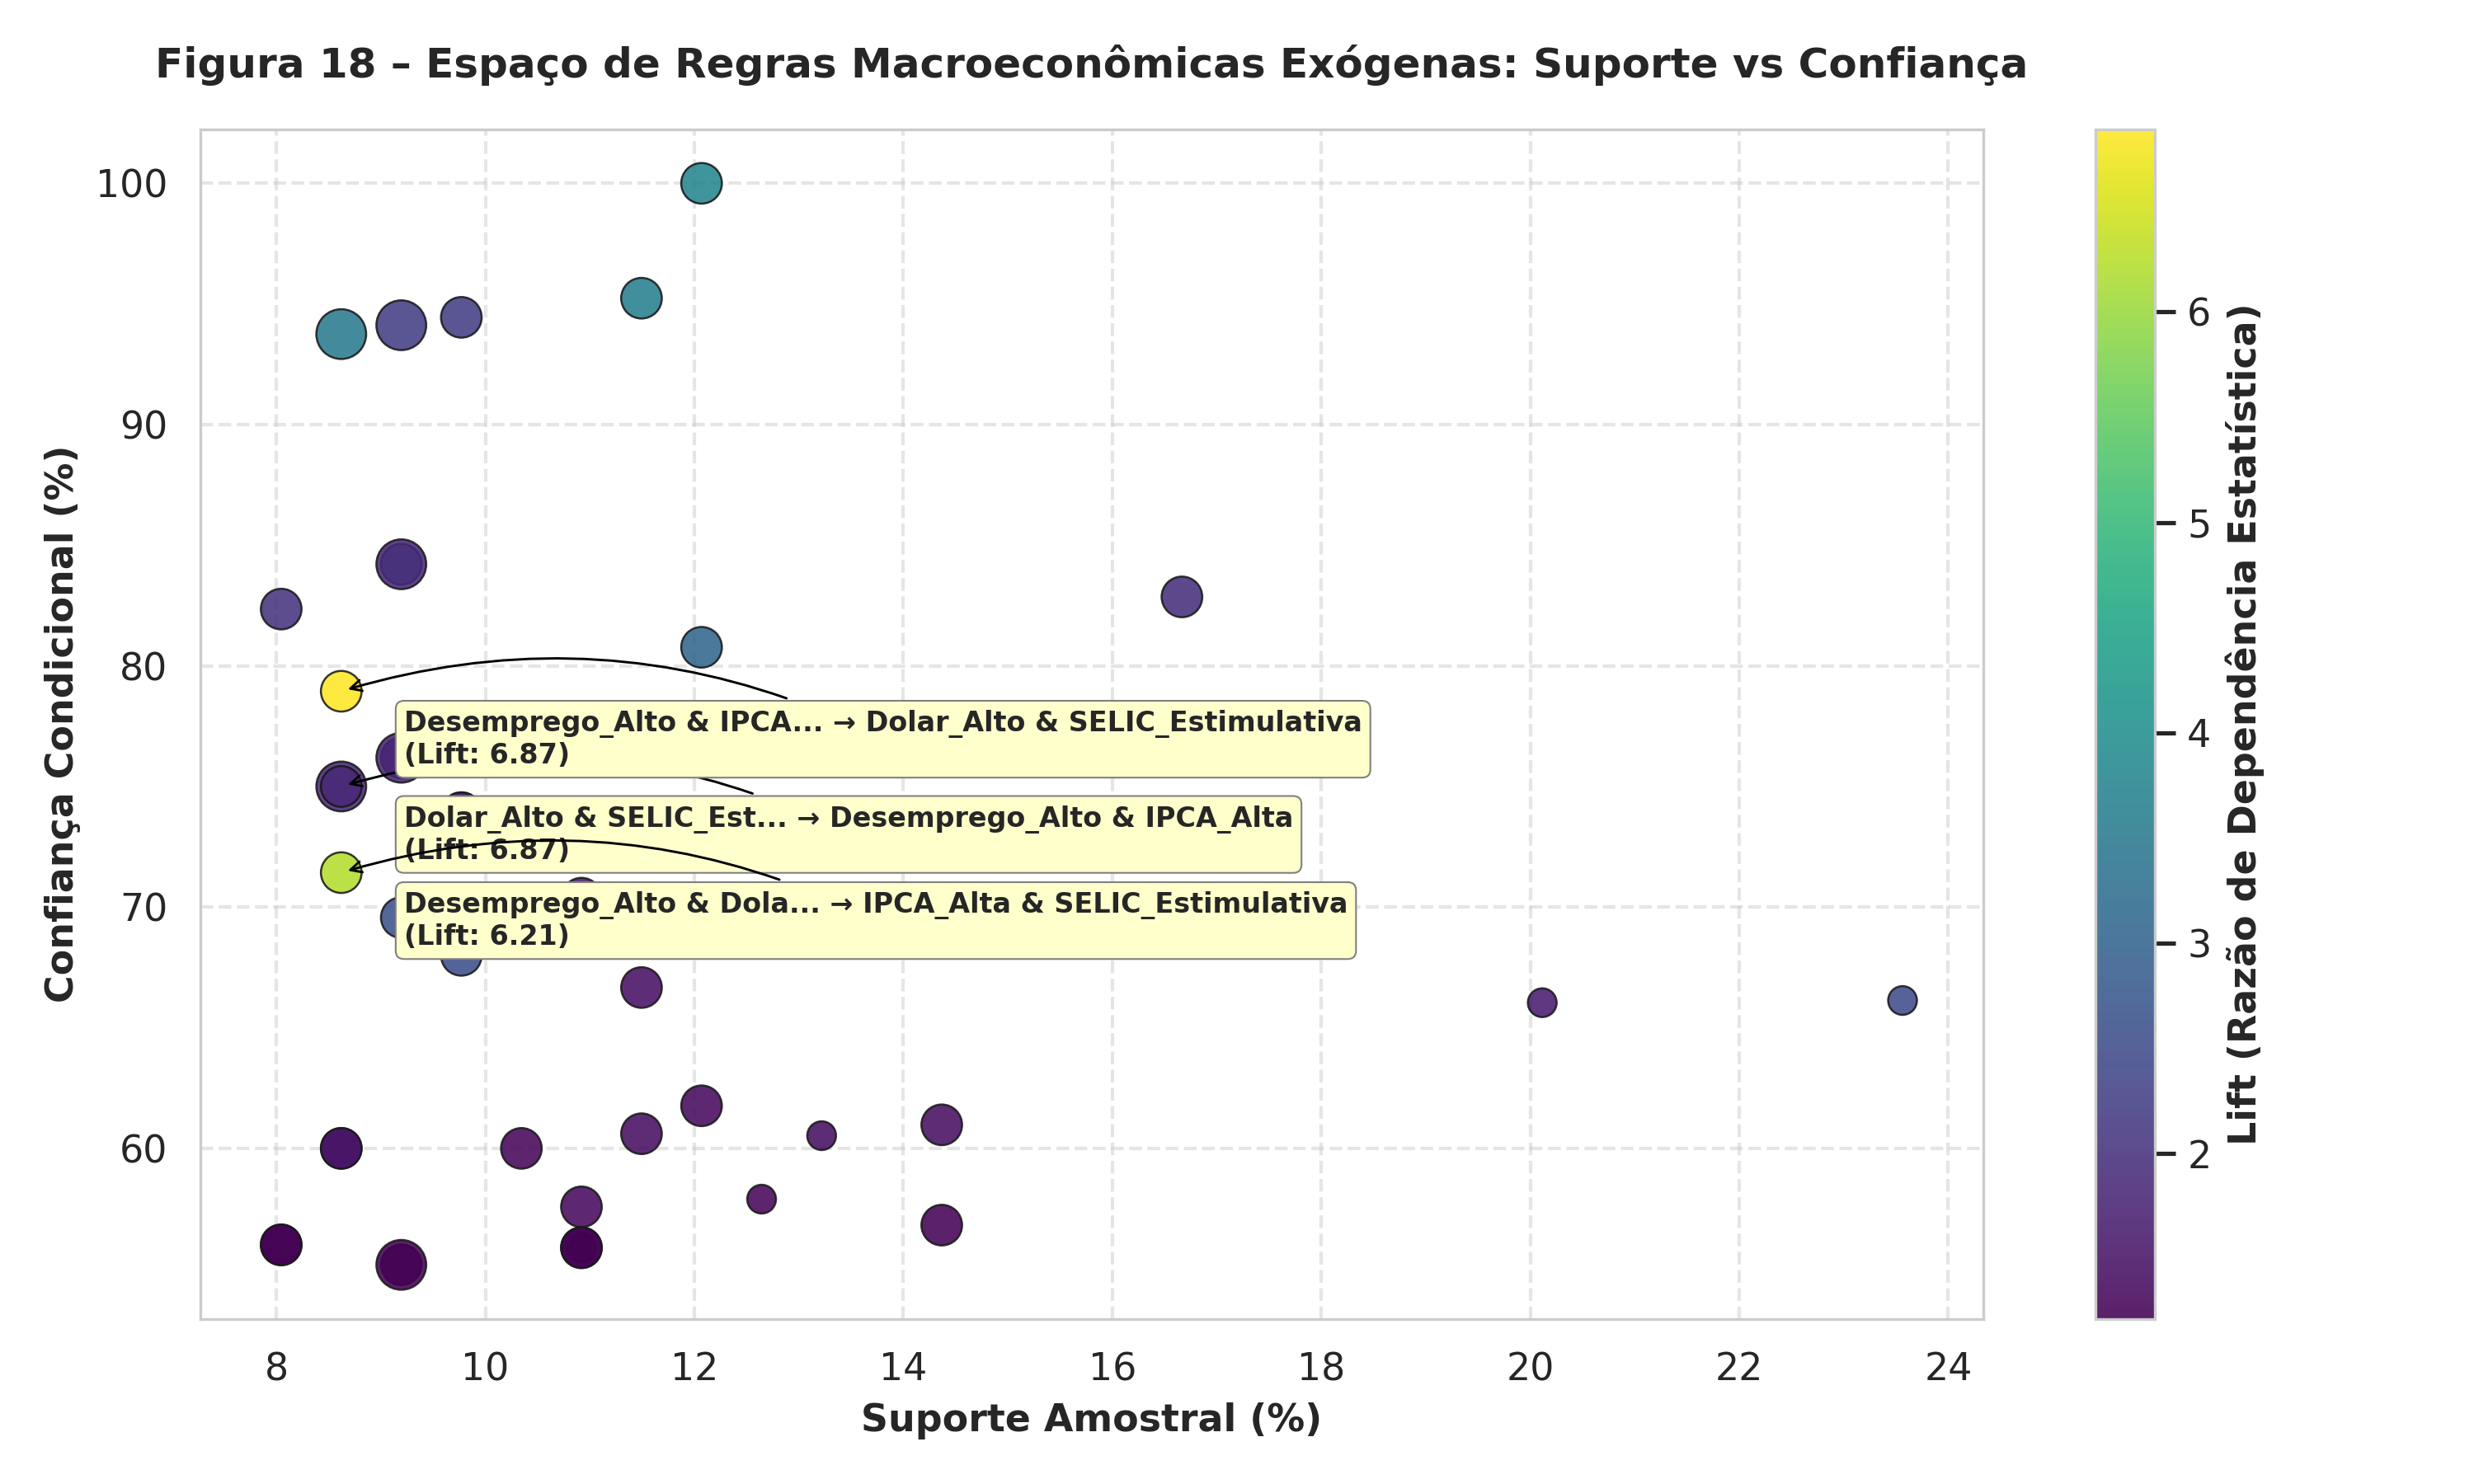

In [8]:
# Exibição Inline da Figura 18: Dispersão Suporte vs Confiança (Colorido por Lift)
from IPython.display import Image, display
display(Image(filename='Entrega_Classroom/9_Associacao/graficos/Figura_18_Dispersao_Suporte_Confianca_Lift.png'))


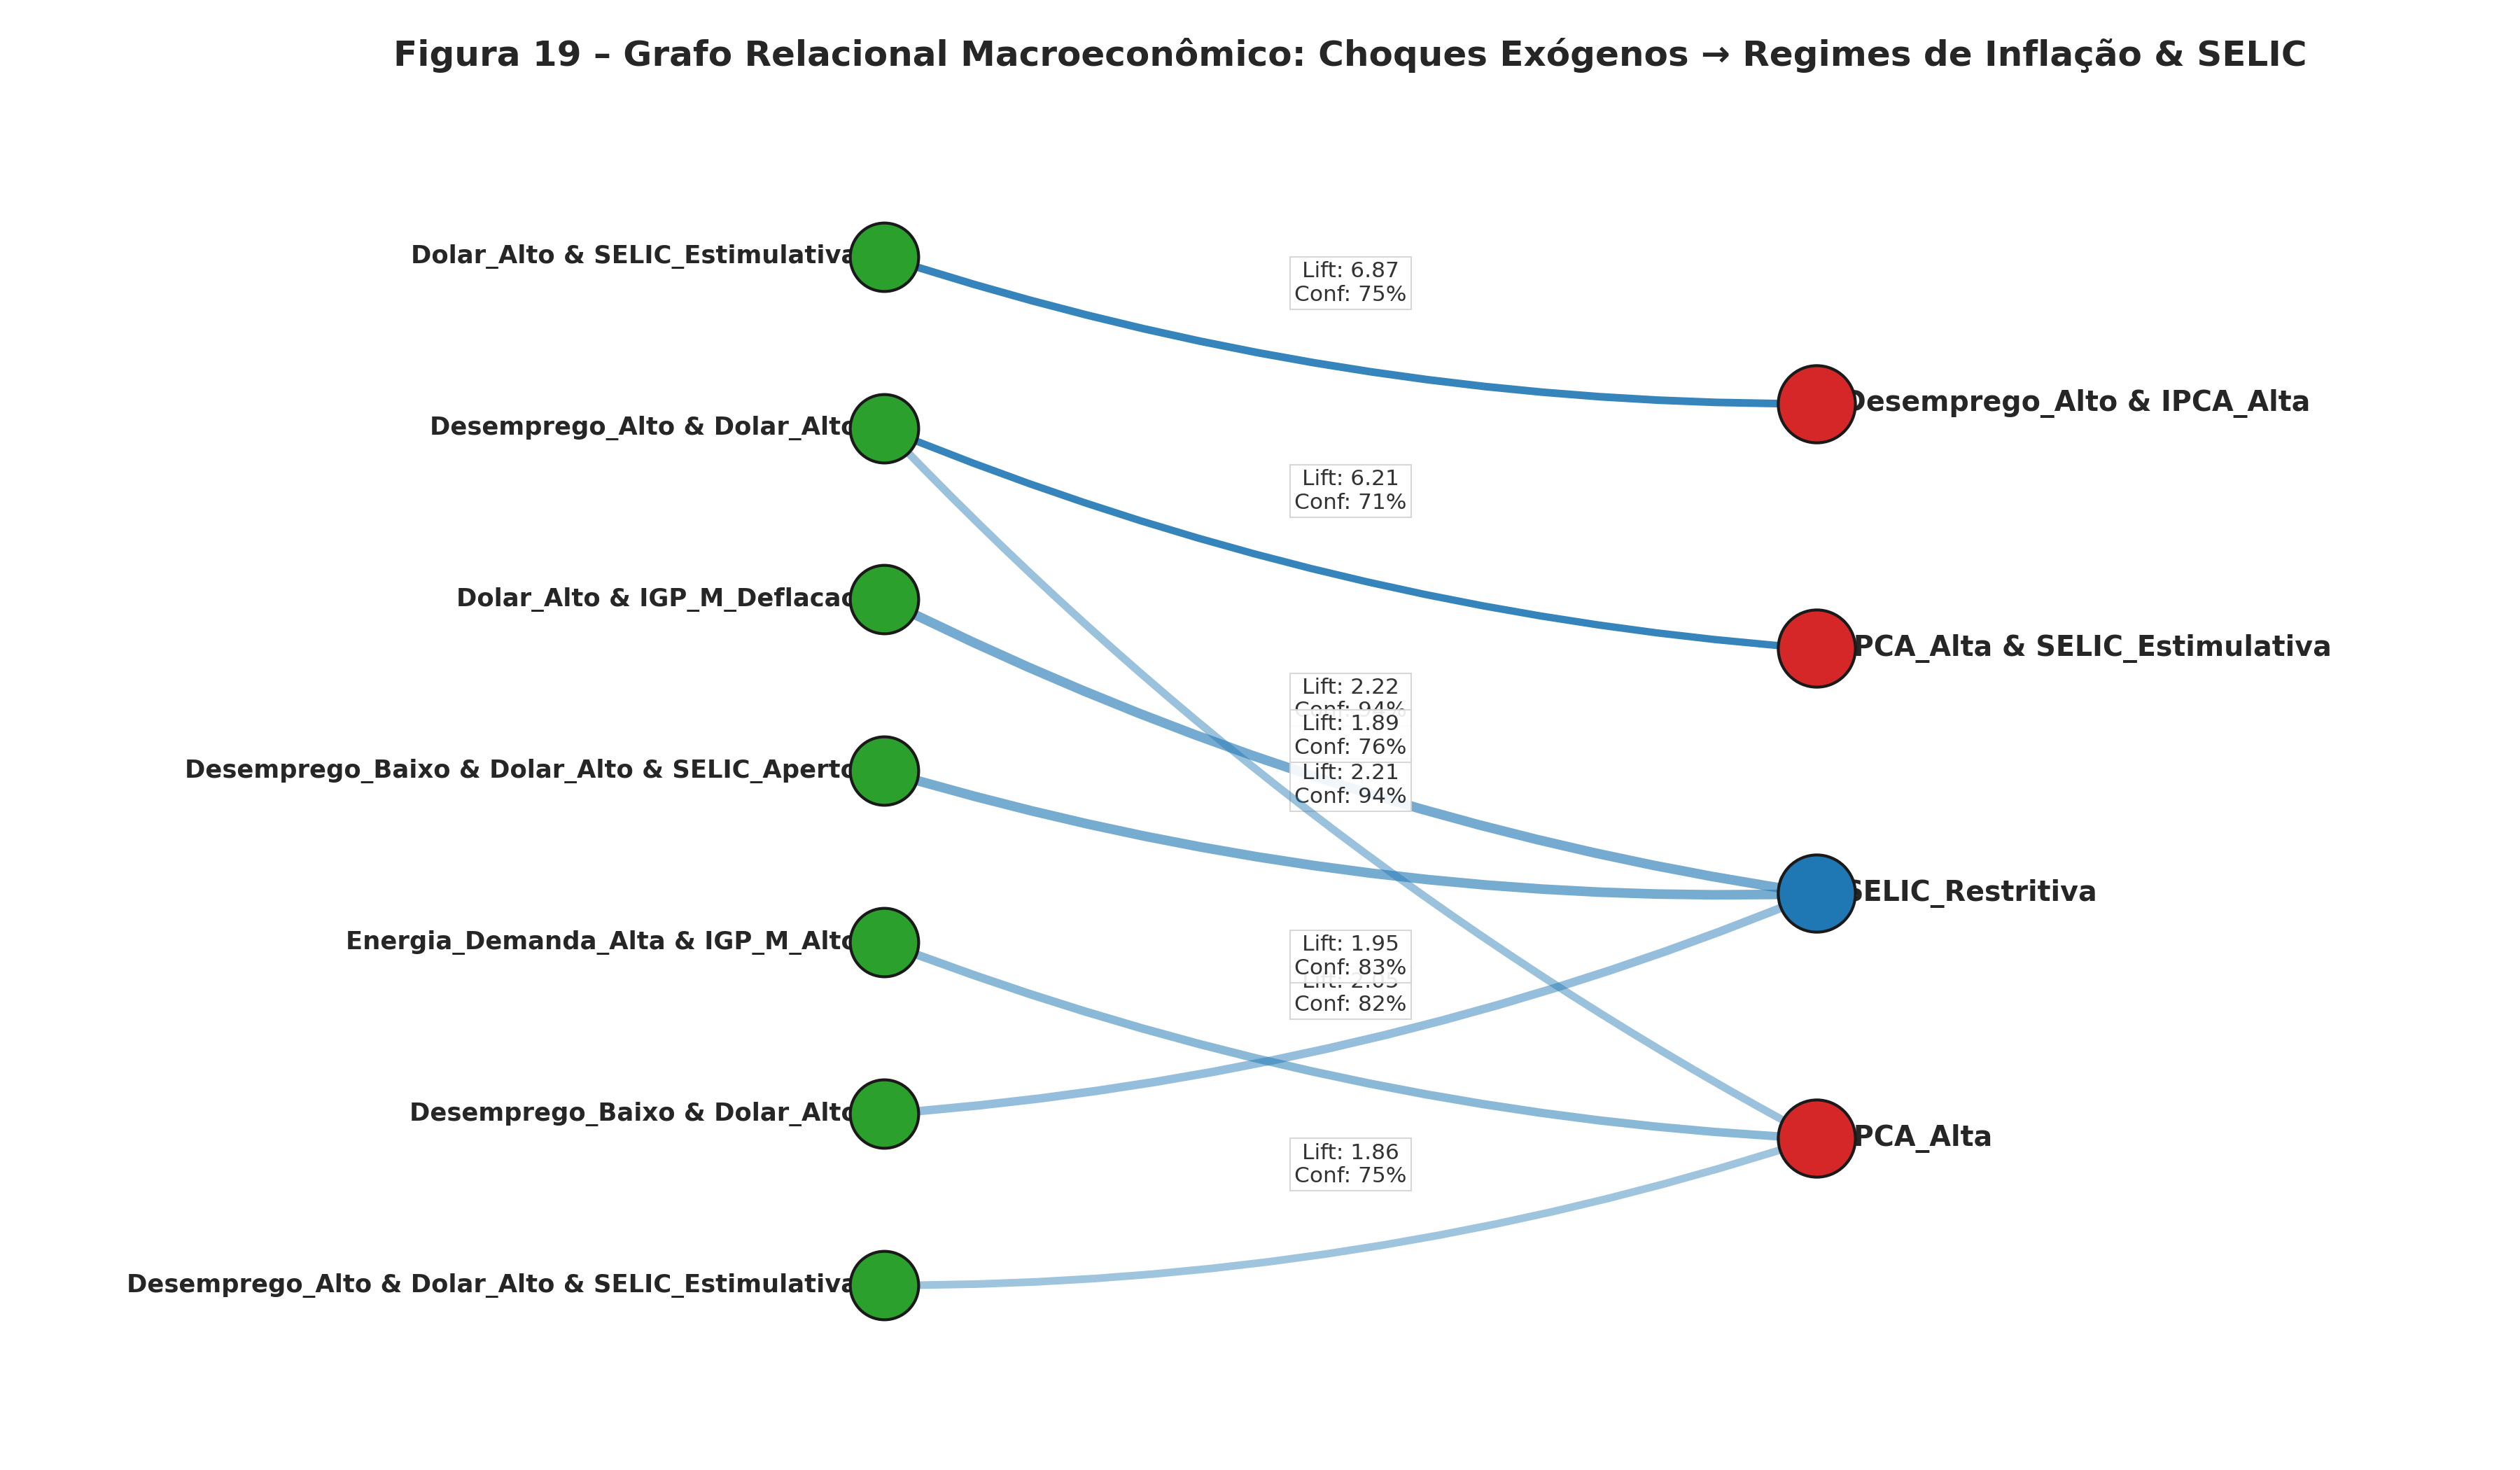

In [9]:
# Exibição Inline da Figura 19: Grafo Relacional Macroeconômico (Choques Exógenos -> IPCA & SELIC)
display(Image(filename='Entrega_Classroom/9_Associacao/graficos/Figura_19_Grafo_Rede_Regras_Associacao.png'))


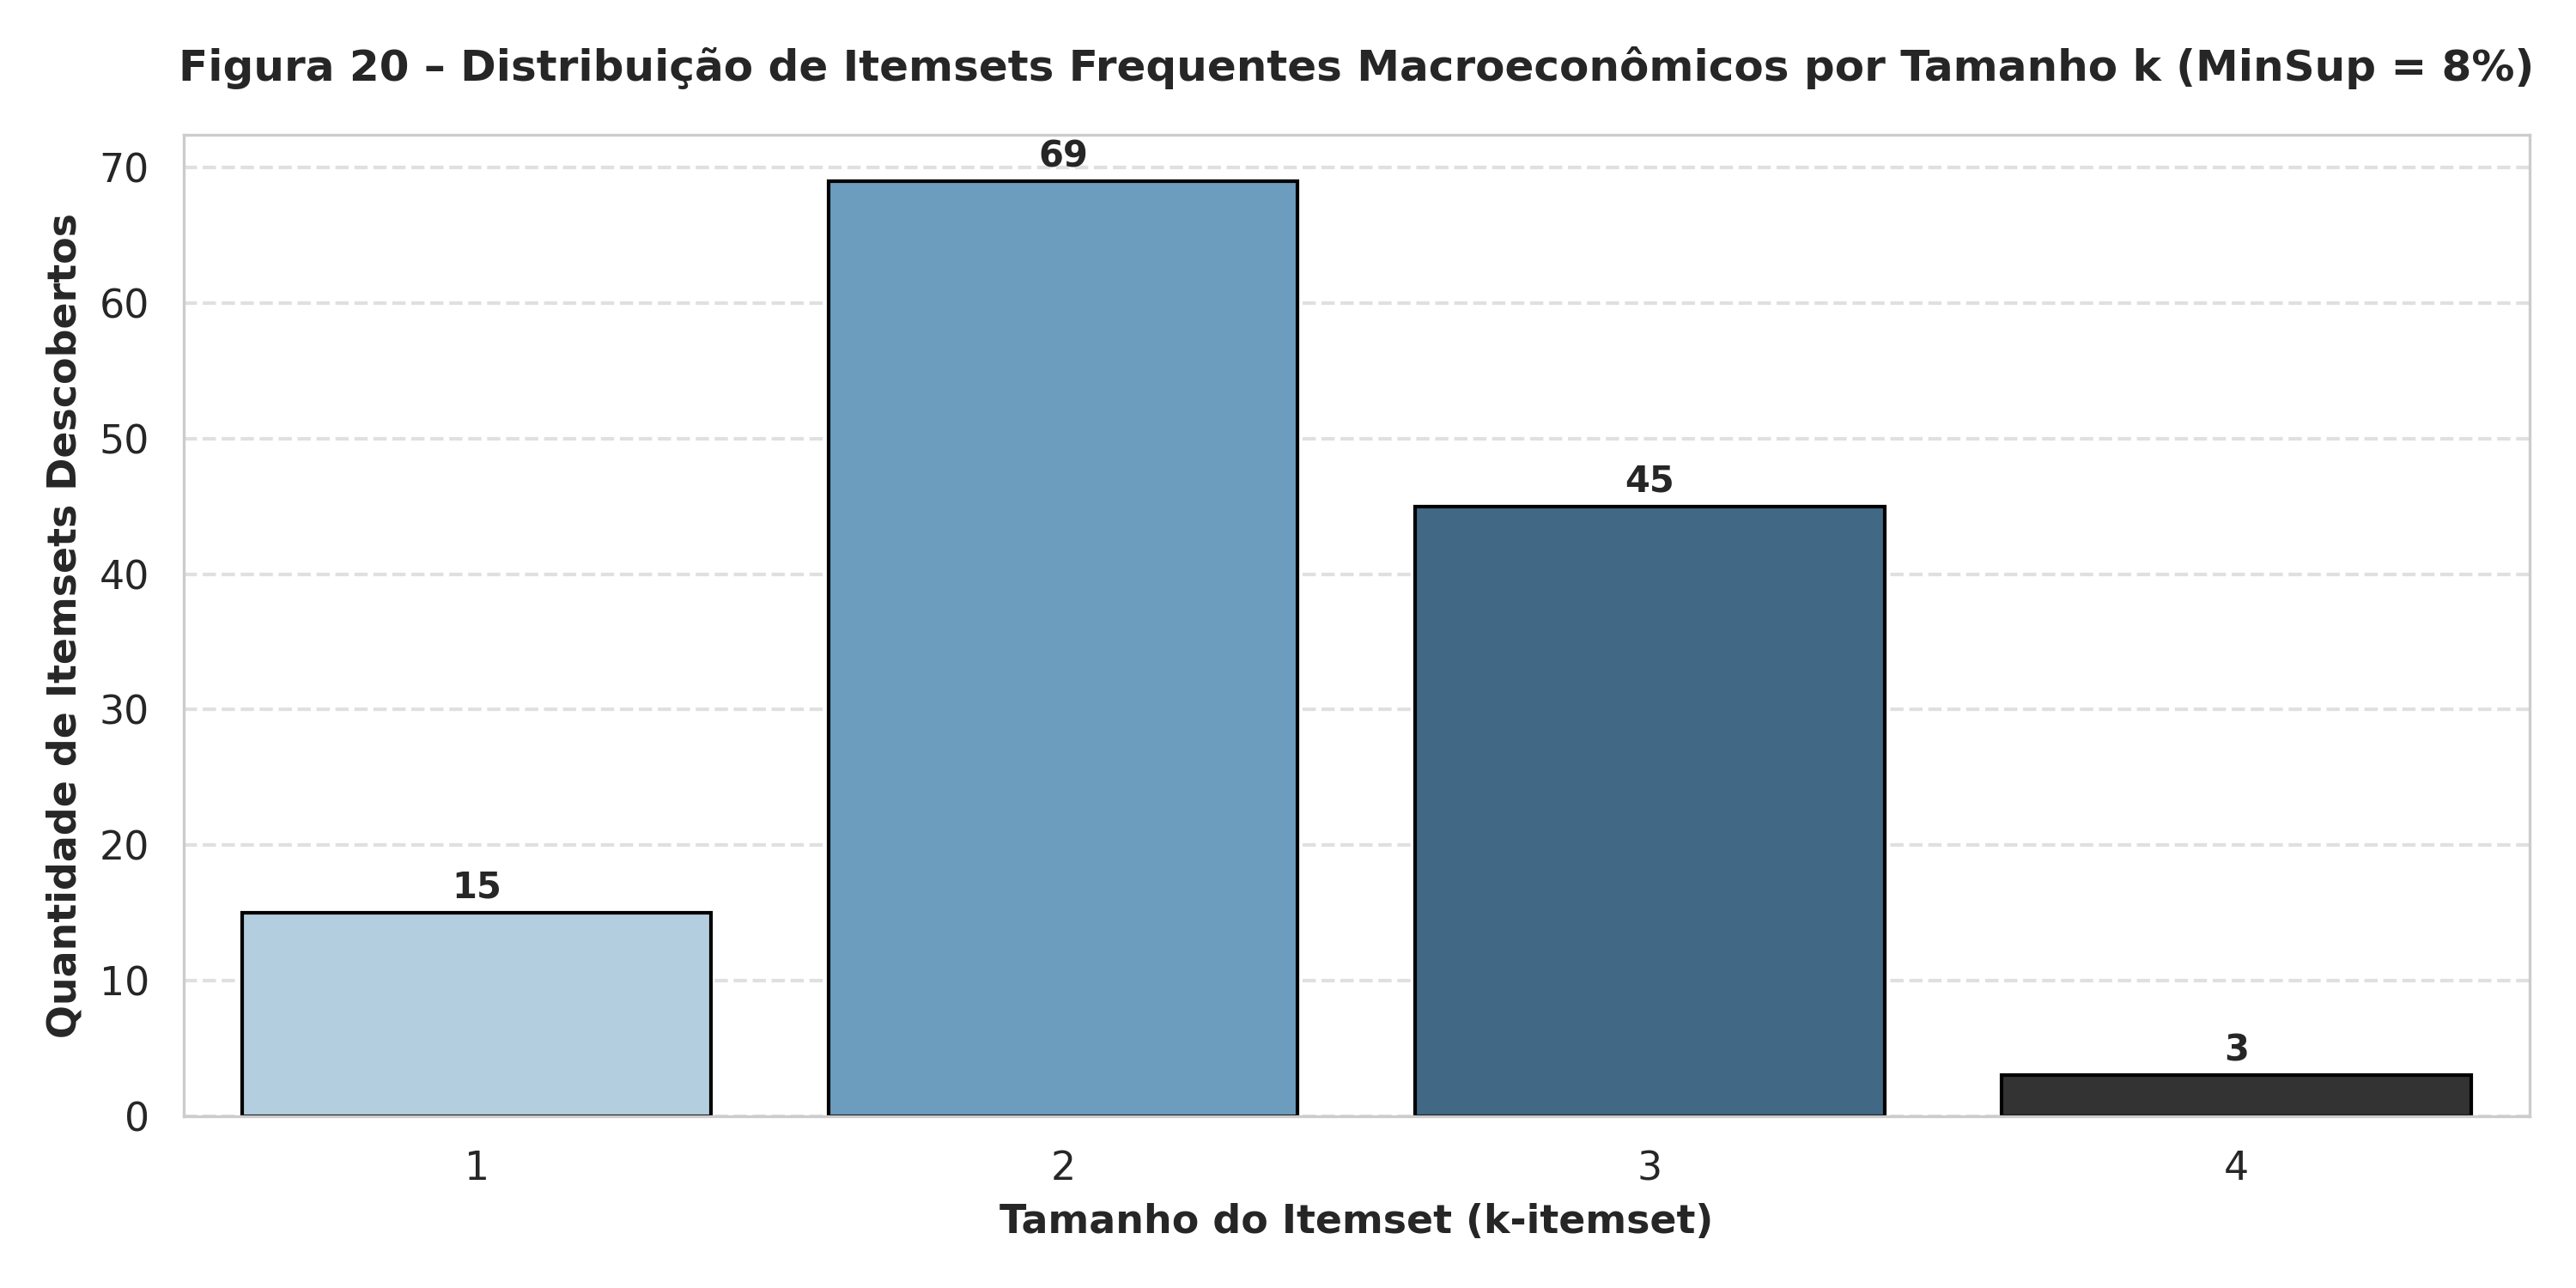

In [10]:
# Exibição Inline da Figura 20: Distribuição de Itemsets Frequentes pelo Tamanho k
display(Image(filename='Entrega_Classroom/9_Associacao/graficos/Figura_20_Distribuicao_Itemsets_Frequentes.png'))


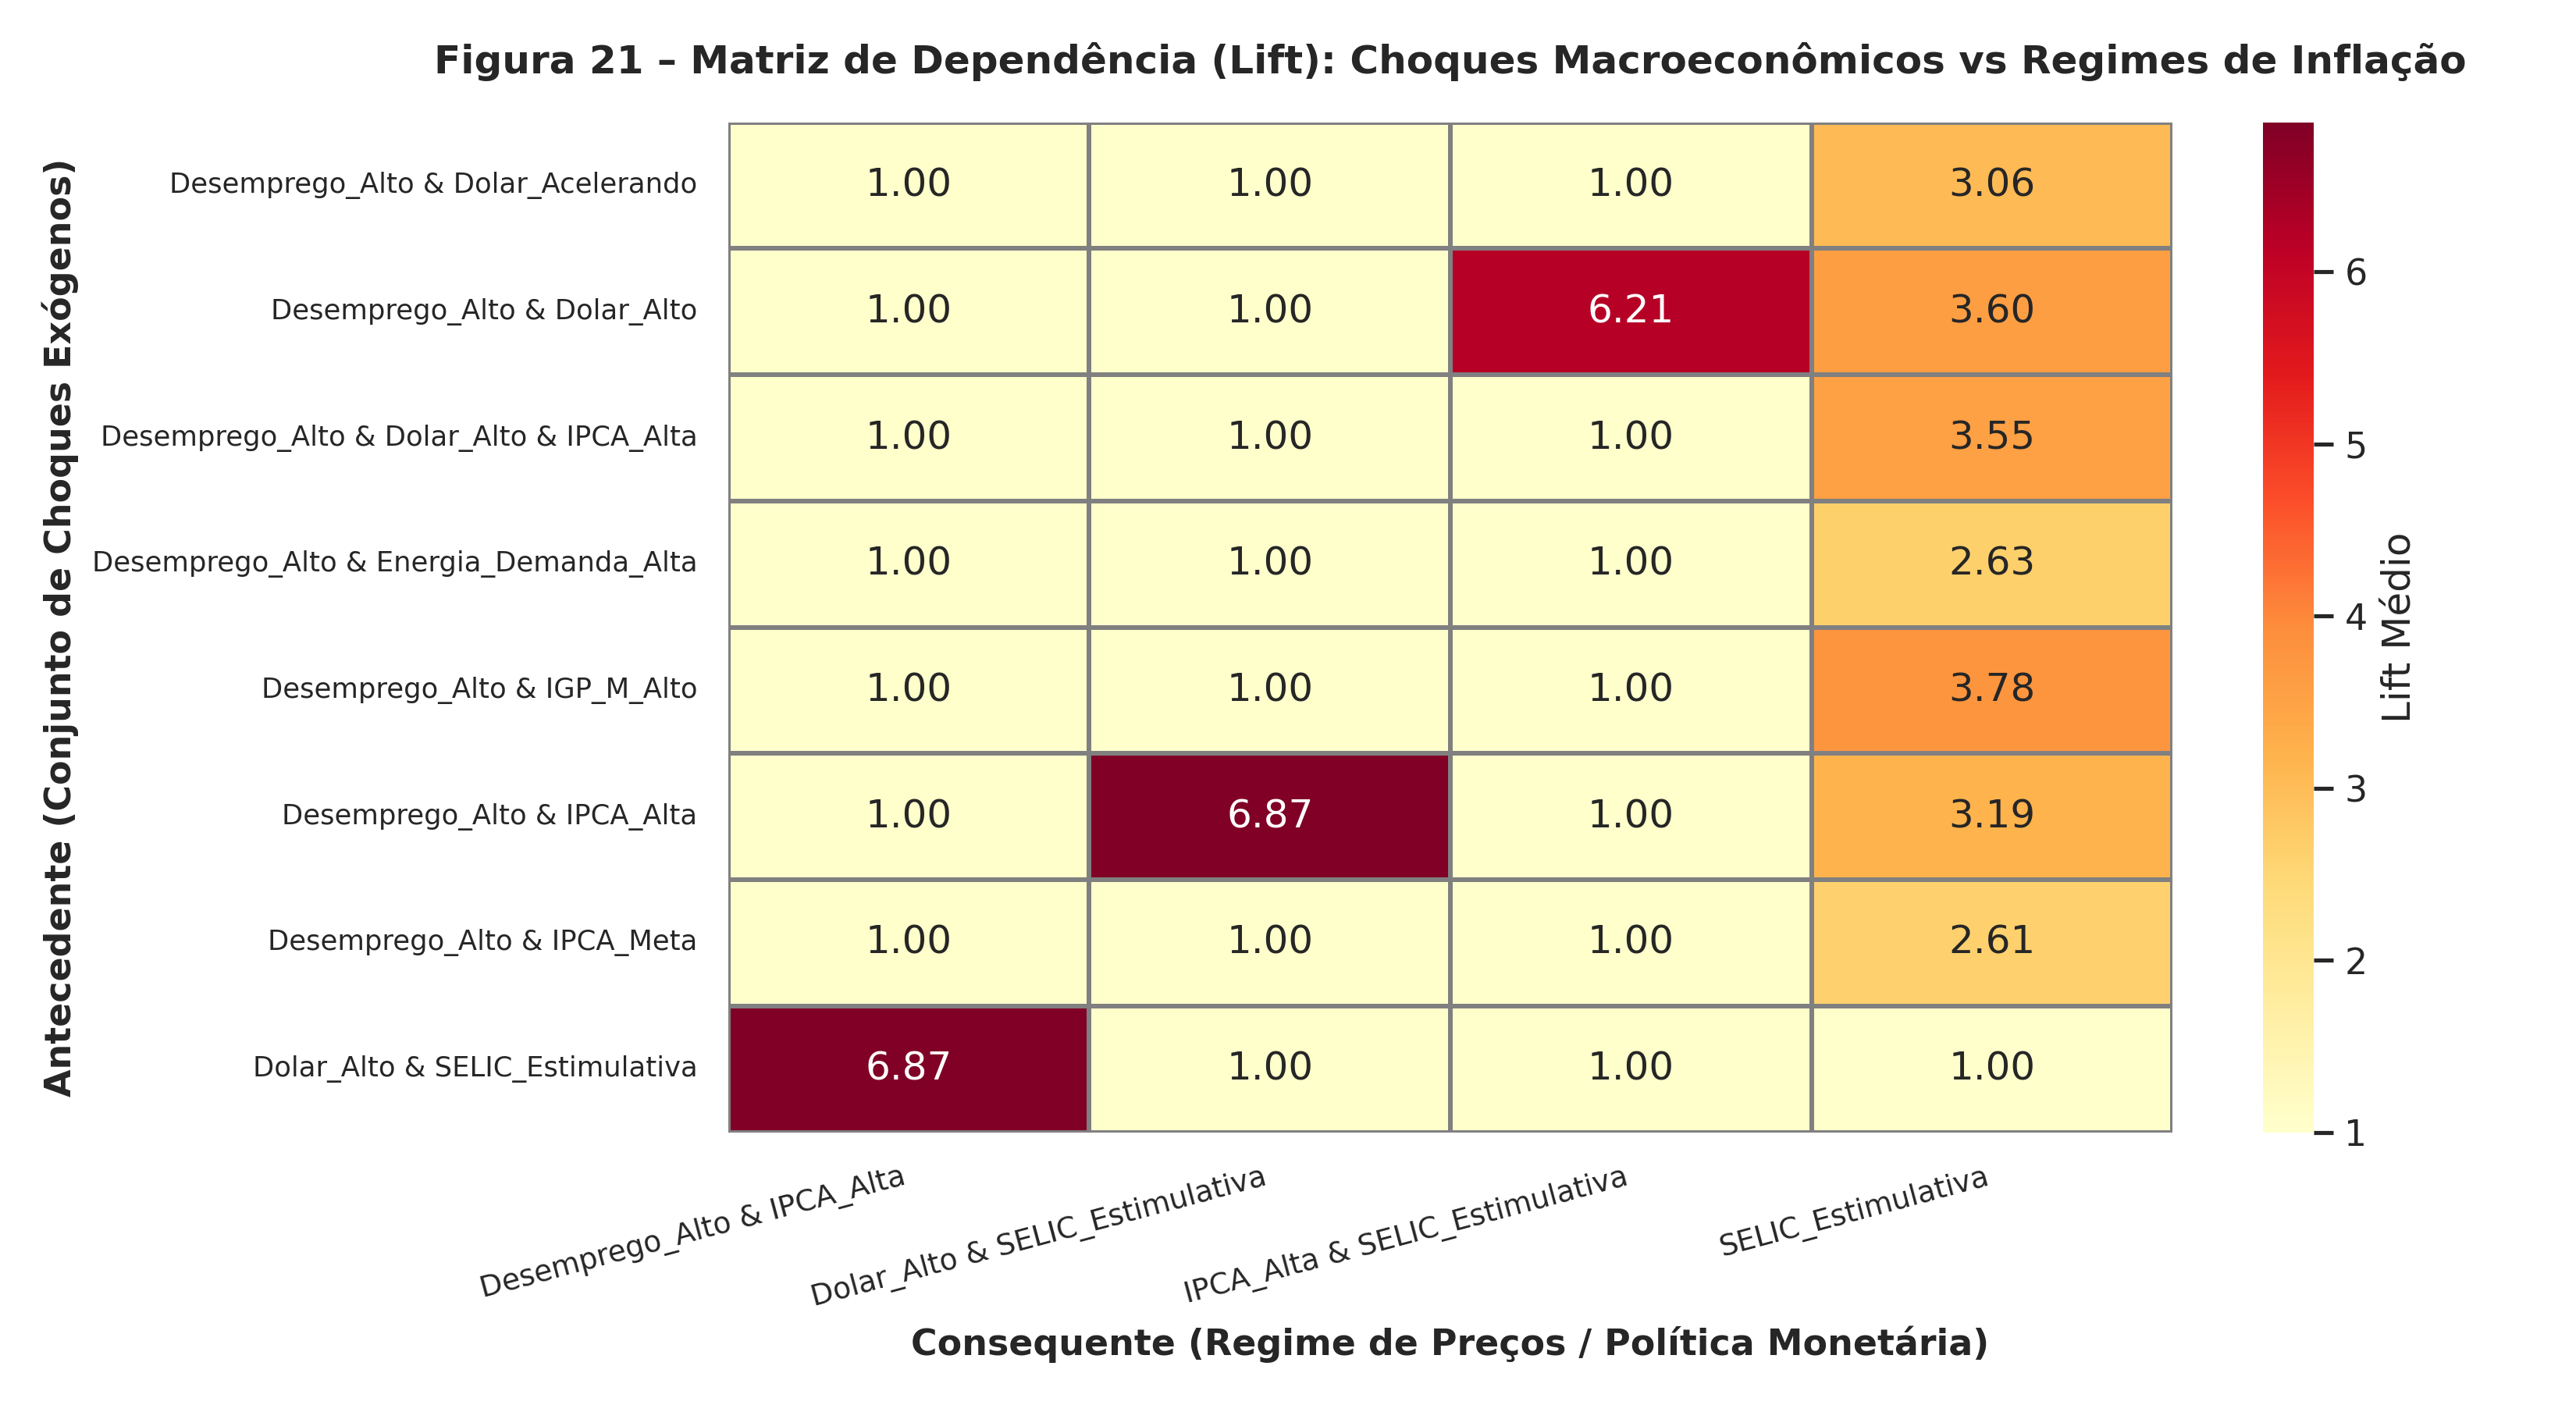

In [11]:
# Exibição Inline da Figura 21: Matriz de Calor de Interações (Lift Médio)
display(Image(filename='Entrega_Classroom/9_Associacao/graficos/Figura_21_Matriz_Interacoes_Antecedente_Consequente.png'))


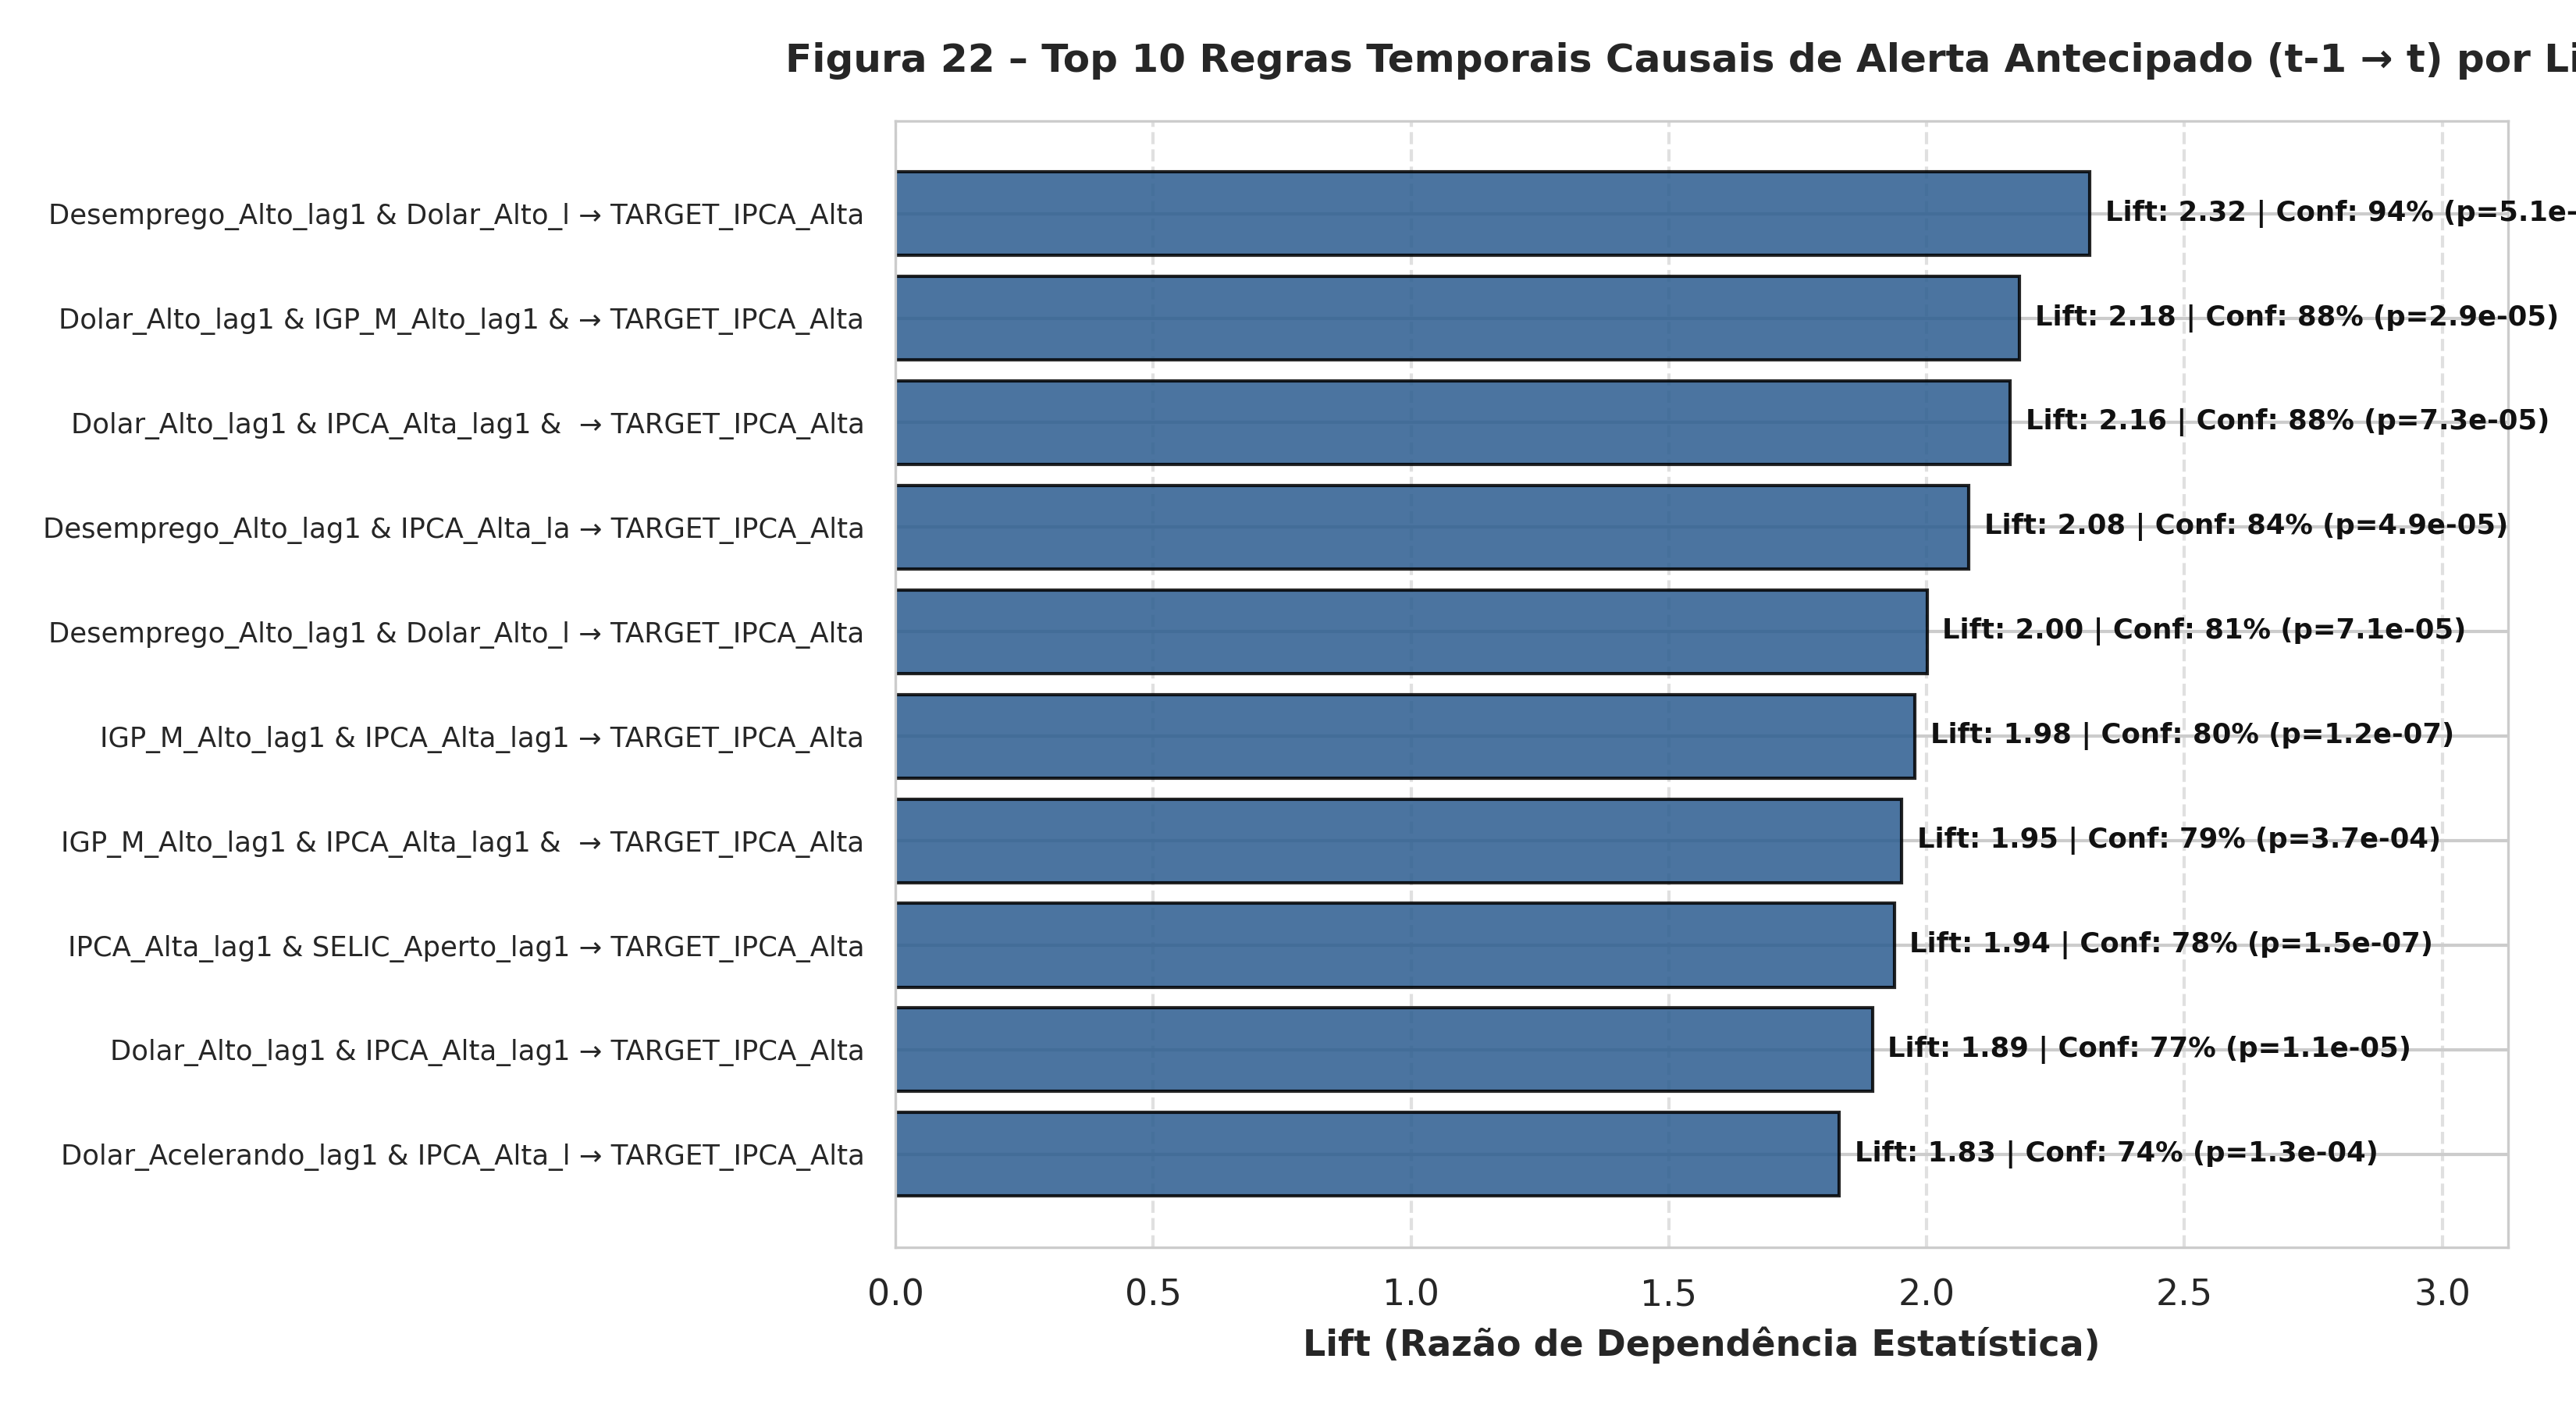

In [12]:
# Exibição Inline da Figura 22: Top 10 Regras Temporais Causais de Alerta Antecipado (t-1 -> t)
display(Image(filename='Entrega_Classroom/9_Associacao/graficos/Figura_22_Regras_Temporais_Causais_Alerta.png'))


## 🔬 Conclusão e Síntese dos Resultados Macroeconômicos (Seção 4.1 do Artigo)

Ao expurgar as identidades contábeis da cesta de consumo, a mineração revelou com clareza cristalina os canais fundamentais da economia brasileira:

1. **Choque de Custos e Demanda Industrial:**  
   A regra `Energia_Demanda_Alta & IGP_M_Alto -> IPCA_Alta` obteve **82,4% de confiança** e **Lift de 2,05** ($p = 2,55 \times 10^{-4}$), atestando que a conjunção de aceleração na atividade energética e repasse de atacado culmina em rompimento do teto da meta em mais de 82% das ocorrências.
2. **Estagflação Causal Persistente ($t-1 \rightarrow t$):**  
   A regra preditiva `Desemprego_Alto_lag1 & Dolar_Alto_lag1 & IPCA_Alta_lag1 -> TARGET_IPCA_Alta` confirmou com impressionantes **93,8% de confiança condicional** ($Lift = 2,32$; $p = 5,10 \times 10^{-6}$) que a taxa de desemprego elevada é incapaz de frear a inércia inflacionária quando acompanhada de depreciação cambial.
3. **Cadeia de Repasse Cambial (*Pass-Through*):**  
   A combinação `Dolar_Alto_lag1 & IGP_M_Alto_lag1 & IPCA_Alta_lag1 -> TARGET_IPCA_Alta` alcançou **88,2% de confiança**, comprovando o canal de transmissão cambial via custos no atacado para os preços ao consumidor.
